In [99]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [100]:
BASE_DIR = os.getcwd()

FITUR = ['Umur (bulan)', 'Berat Badan (kg)', 'Jenis Kelamin']
TARGET = 'Status Gizi'
df = pd.read_csv(
    os.path.join(BASE_DIR, "dataset_berat_balita.csv")
)

df.head()

,Umur (bulan),Berat Badan (kg),Jenis Kelamin,Status Gizi
0,0,1,perempuan,severely underweight
1,0,6,perempuan,overweight
2,0,1,perempuan,severely underweight
3,0,6,perempuan,overweight
4,0,4,perempuan,normal


In [101]:
#mapping
df['Jenis Kelamin'] = df['Jenis Kelamin'].map({'laki-laki': 0, 'perempuan': 1})
df[TARGET] = df[TARGET].map({'severely underweight': 0, 'underweight': 1,
                             'normal': 2, 'overweight': 3})

#remove NAN
df = df.dropna(subset=FITUR + [TARGET])
df

,Umur (bulan),Berat Badan (kg),Jenis Kelamin,Status Gizi
0,0,1,1,0
1,0,6,1,3
2,0,1,1,0
3,0,6,1,3
4,0,4,1,2
...,...,...,...,...
122117,60,18,0,2
122118,60,21,0,2
122119,60,25,0,3
122120,60,19,0,2


In [102]:
#remove duplicate
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)} after drop_duplicates")


X = df[FITUR]
y = df[TARGET]

df


Rows: 122122 -> 2372 after drop_duplicates


,Umur (bulan),Berat Badan (kg),Jenis Kelamin,Status Gizi
0,0,1,1,0
1,0,6,1,3
2,0,4,1,2
3,0,4,1,3
4,0,7,1,3
...,...,...,...,...
2367,60,21,0,3
2368,60,22,0,3
2369,60,21,0,2
2370,60,28,0,3


In [103]:
#split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X

,Umur (bulan),Berat Badan (kg),Jenis Kelamin
0,0,1,1
1,0,6,1
2,0,4,1
3,0,4,1
4,0,7,1
...,...,...,...
2367,60,21,0
2368,60,22,0
2369,60,21,0
2370,60,28,0


In [104]:

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=10, gamma='scale')),
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='accuracy')
for i, s in enumerate(scores, 1):
    print(f"Fold {i} Accuracy: {s*100:.2f}%")
print(f"Mean CV Accuracy: {scores.mean()*100:.2f}%")

Fold 1 Accuracy: 84.21%
Fold 2 Accuracy: 82.63%
Fold 3 Accuracy: 83.11%
Fold 4 Accuracy: 82.59%
Fold 5 Accuracy: 84.17%
Mean CV Accuracy: 83.34%


                      precision    recall  f1-score   support

severely underweight       0.82      0.91      0.87       103
         underweight       0.59      0.43      0.50        61
              normal       0.76      0.83      0.80       132
          overweight       0.92      0.89      0.91       179

            accuracy                           0.82       475
           macro avg       0.78      0.77      0.77       475
        weighted avg       0.82      0.82      0.82       475

Akurasi test: 82.11%


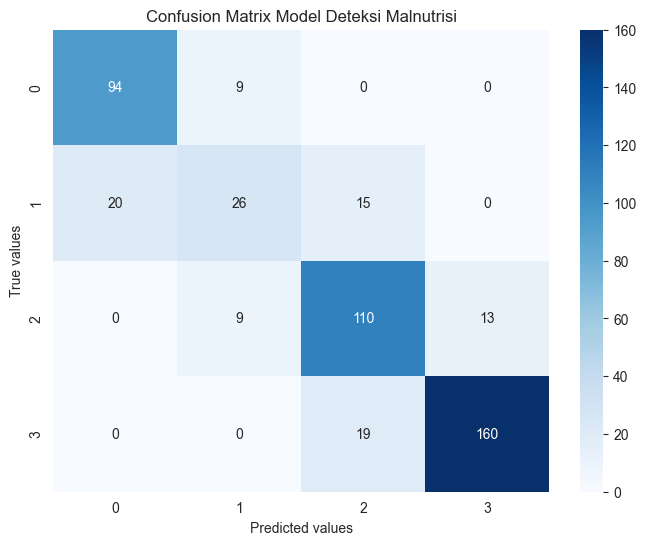

In [105]:
# 5. Fit final di seluruh data train, evaluasi di data test
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2, 3],
    target_names=['severely underweight', 'underweight', 'normal', 'overweight'],
    zero_division=0))
print(f"Akurasi test: {accuracy_score(y_test, y_pred)*100:.2f}%")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])
plt.figure(figsize=(8, 6))
sn.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted values')
plt.ylabel('True values')
plt.title('Confusion Matrix Model Deteksi Malnutrisi')
plt.savefig(os.path.join(BASE_DIR, "confusion_matrix.png"), dpi=150, bbox_inches='tight')
plt.show()

In [106]:
model_path =   os.path.join(BASE_DIR, "nutrion.pkl")

joblib.dump(pipeline, model_path)

['/Users/macbook/Downloads/posyandu-ai/nutrion.pkl']

In [107]:
#try dump model
model_path = os.path.join(BASE_DIR, "nutrion.pkl")
test_model = joblib.load(model_path)

test_model_stunting = pd.DataFrame({
    'Umur (bulan)': [45],
    'Berat Badan (kg)': [22],
    'Jenis Kelamin': [0],   # 0 = laki-laki, 1 = perempuan
})[FITUR]

y_pred_train = test_model.predict(X_train)
y_pred_test = test_model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

pred = test_model.predict(test_model_stunting)
print("Predicted Score = {}".format(np.array(pred)))


Training Accuracy: 0.8502899314707433
Test Accuracy: 0.8210526315789474
Predicted Score = [3]
